In [1]:
from pathlib import Path
pasta_projeto = Path.cwd()
extensões = {".jpg" , ".jpeg" , "png" , ".webp"}
imagens = [arquivo for arquivo in pasta_projeto.rglob("*") if arquivo.suffix.lower() and ".ipynb_checkpoints" not in arquivo.parts ]
print("pasta do projeto:" , pasta_projeto)
print("qauntidade de imagens encontradas:" , len(imagens))
for imagem in imagens[:5]:
    print(imagem)

pasta do projeto: C:\Users\User\Documents\insper\machine learning\projeto-final-machine-learning
qauntidade de imagens encontradas: 2279
C:\Users\User\Documents\insper\machine learning\projeto-final-machine-learning\Football And Player Detection.v10i.yolov8
C:\Users\User\Documents\insper\machine learning\projeto-final-machine-learning\gan_futebol_30_epocas.pth
C:\Users\User\Documents\insper\machine learning\projeto-final-machine-learning\projeto_final.ipynb
C:\Users\User\Documents\insper\machine learning\projeto-final-machine-learning\Football And Player Detection.v10i.yolov8\data.yaml
C:\Users\User\Documents\insper\machine learning\projeto-final-machine-learning\Football And Player Detection.v10i.yolov8\README.dataset.txt


quantidade real de imagens: 1128


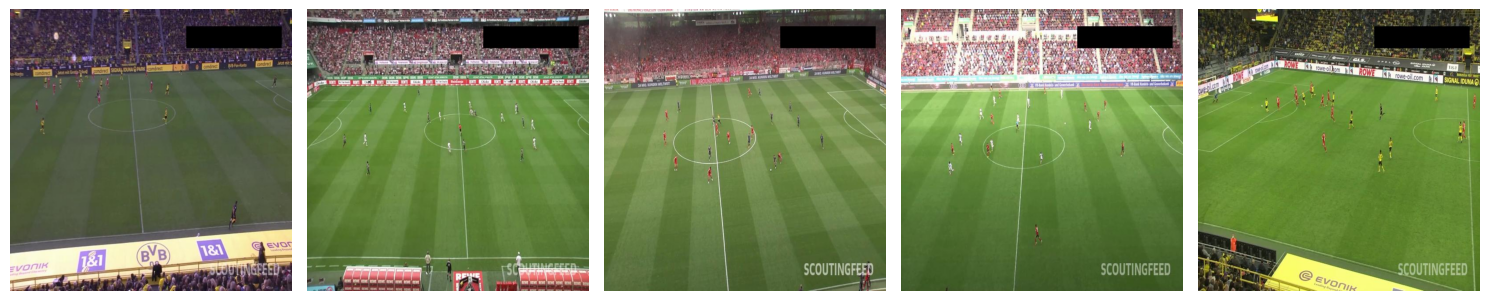

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

pasta_dataset = Path("Football And Player Detection.v10i.yolov8")
extensoes = {".jpg" , ".jpeg" , ".png" , ".wepg"}
imagens = sorted([ arquivo for arquivo in pasta_dataset.rglob("*") if arquivo.is_file() and arquivo.suffix.lower() in extensoes ])
print("quantidade real de imagens:" , len(imagens))
if len(imagens) > 0:
    fig, axes = plt.subplots(1 , min(5, len(imagens)), figsize = (15, 4))
    if len(imagens) == 1:
        axes = [axes]
    for ax, caminho in zip(axes, imagens[:5]):
        with Image.open(caminho) as img:
            ax.imshow(img.convert("RGB"))
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("nenhuma imagem encontrada")

In [3]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMG_SIZE = 64
BATCH_SIZE = 32

transform = transforms.Compose([ transforms.Resize(( IMG_SIZE , IMG_SIZE)), transforms.ToTensor(), transforms.Normalize ( mean = [0.5 , 0.5 , 0.5] , std = [0.5 , 0.5 , 0.5] ) ])

class FutebolDataset(Dataset):
        def __init__(self, imagens, transform = None):
            self.imagens = imagens
            self.transform = transform

        def __len__(self):
            return len(self.imagens)

        def __getitem__(self , idx):
            imagem = Image.open(self.imagens[idx]).convert("RGB")

            if self.transform:
                imagem = self.transform(imagem)

            return imagem

dataset = FutebolDataset(imagens, transform)
dataloader = DataLoader(dataset, batch_size = BATCH_SIZE , shuffle = True , num_workers = 0 )
device = torch.device( "cuda" if torch.cuda.is_available() else "cpu" )
print("dispositivo" , device)
print("quantidade de imagens" , len(dataset))
print("qauntidade de batches" , len(dataloader))

batch = next(iter(dataloader))
print("formato do batch" , batch.shape)

         
        

dispositivo cpu
quantidade de imagens 1128
qauntidade de batches 36
formato do batch torch.Size([32, 3, 64, 64])


In [5]:
import torch.nn as nn

LATENT_DIM = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
        nn.ConvTranspose2d(LATENT_DIM, 256, 4, 1, 0, bias = False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.ConvTranspose2d(256, 128, 4, 2, 1, bias = False),
        nn.BatchNorm2d(128),
        nn.ReLU(True),
        nn.ConvTranspose2d(128, 64, 4, 2, 1, bias = False),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.ConvTranspose2d(64, 32, 4, 2, 1, bias = False),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.ConvTranspose2d(32, 3, 4, 2, 1, bias = False),
        nn.Tanh()
        )
    def forward(self, z):
        return self.model(z)


generator = Generator().to(device)
ruido = torch.randn(1, LATENT_DIM, 1, 1).to(device)
imagem_gerada = generator(ruido)
print("formato da imagem gerada:" , imagem_gerada.shape)

formato da imagem gerada: torch.Size([1, 3, 64, 64])


In [6]:

import torch
import torch.nn as nn

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x).view(-1)

discriminator = Discriminator().to(device)

# Testar o discriminador com imagens reais
batch = next(iter(dataloader)).to(device)

resultado = discriminator(batch)

print("Formato da saída:", resultado.shape)
print("Primeiras probabilidades:", resultado[:5])


Formato da saída: torch.Size([32])
Primeiras probabilidades: tensor([0.4329, 0.5122, 0.5653, 0.3885, 0.5362], grad_fn=<SliceBackward0>)


In [7]:
import torch.optim as optim
criterion = nn.BCELoss()
learning_rate = 0.0002
optimizer_G = optim.Adam(generator.parameters(), lr = learning_rate, betas = (0.5 , 0.999) )
optimizer_D = optim.Adam(discriminator.parameters(), lr = learning_rate, betas = (0.5 , 0.999))
NUM_EPOCHS = 100
print("Função de perda:" , criterion)
print("taxa de aprendizado" , learning_rate)
print("numero de época" , NUM_EPOCHS)
print("otimizadores configurados com sucesso")

Função de perda: BCELoss()
taxa de aprendizado 0.0002
numero de época 100
otimizadores configurados com sucesso


In [9]:
generator.train()
discriminator.train()
historico_G = []
historico_D = []
for epoch in range(NUM_EPOCHS):
    perda_G_total = 0
    perda_D_total = 0
    for i, imagens_reais in enumerate(dataloader):
        imagens_reais = imagens_reais.to(device)
        batch_size = imagens_reais.size(0)
        reais = torch.ones(batch_size, device = device)
        falsas = torch.zeros(batch_size, device = device)
        optimizer_D.zero_grad()
        saida_real = discriminator(imagens_reais)
        loss_real = criterion(saida_real, reais)
        ruido = torch.randn(batch_size, LATENT_DIM, 1, 1, device = device)
        imagens_falsas = generator(ruido)
        saida_falsa = discriminator(imagens_falsas.detach())
        loss_fake = criterion(saida_falsa, falsas)
        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()
        for parametro in discriminator.parameters():
             parametro.requires_grad_(False)

        optimizer_G.zero_grad()

        saida_falsa = discriminator(imagens_falsas)
        loss_G = criterion(saida_falsa, reais)

        loss_G.backward()
        optimizer_G.step()

        for parametro in discriminator.parameters():
            parametro.requires_grad_(True)
        perda_D_total += loss_D.item()
        perda_G_total = loss_G.item()
    media_D = perda_D_total / len(dataloader)
    media_G = perda_G_total / len(dataloader)
    historico_D.append(media_D)
    historico_G.append(media_G)
    print(f"Época [{epoch+1}/{NUM_EPOCHS}] "
        f"Loss D: {media_D:.4f} | "
        f"Loss G: {media_G:.4f}",
        flush=True)
print("Treinamneto concluido")

KeyboardInterrupt: 

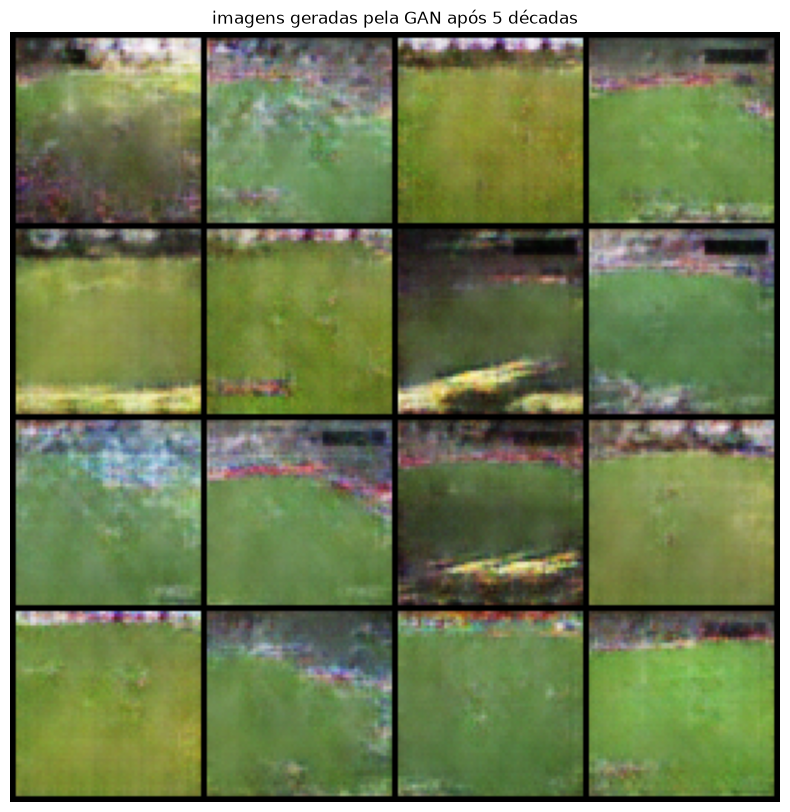

In [10]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

generator.eval()
with torch.no_grad():
    ruido = torch.randn(16, LATENT_DIM, 1, 1, device = device)
    imagens_geradas = generator(ruido)
imagens_geradas = (imagens_geradas + 1)/2
grade = make_grid(imagens_geradas.cpu(), nrow = 4, padding = 2)
plt.figure(figsize = (10, 10))
plt.imshow(grade.permute(1, 2, 0).numpy())
plt.axis("off")
plt.title("imagens geradas pela GAN após 5 décadas")
plt.show()

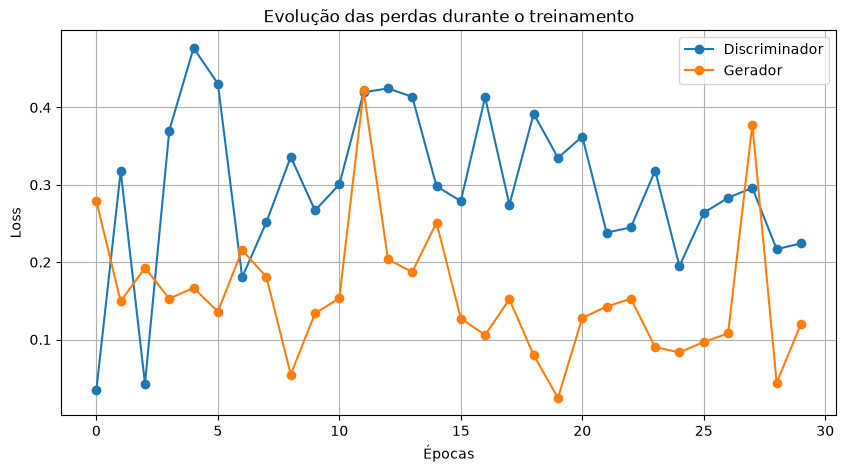

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(historico_D, label="Discriminador", marker="o")
plt.plot(historico_G, label="Gerador", marker="o")

plt.title("Evolução das perdas durante o treinamento")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Salvar o estado atual da GAN
torch.save({
    "generator": generator.state_dict(),
    "discriminator": discriminator.state_dict(),
    "optimizer_G": optimizer_G.state_dict(),
    "optimizer_D": optimizer_D.state_dict(),
    "historico_G": historico_G,
    "historico_D": historico_D,
    "epocas": len(historico_G)
}, "gan_futebol_30_epocas.pth")

print("Modelo salvo com sucesso!")
